# Universidad Panamericana Campus Aguascalientes
## Maestría en Inteligencia Artificial y Ciencia de Datos
### Deep Learning

**Assignment.** Linear Regression from Scratch vs Scikit-Learn — Predicting MEDV from RM (Boston Housing Dataset)

ID: 0286155

Student: Manuel Alejandro Serrano Macias

**Objective:**
Reuse the baseline NumPy linear regression functions from `Linear_Regression_Numpy.ipynb`
to predict **MEDV** using **RM**, then compare against **scikit-learn's LinearRegression**.


## Part 1 – Data Loading and Exploration

In [1]:
import pandas as pd
import numpy as np

# Read the Boston housing data. Each row is one neighbourhood.
df = pd.read_csv('boston.csv')

# We only use two columns:
#   RM   = average number of rooms per home  -> the input
#   MEDV = middle house price, in $1000s     -> what we predict
# Bigger homes should cost more, so we try to fit a line.

# The double brackets keep X as a table with one column.
X = df[['RM']].values

# reshape(-1, 1) puts the prices in one column so they line up with X.
y = df['MEDV'].values.reshape(-1, 1)


In [2]:
print('Dataset shape:', df.shape)
print()

# Basic statistics of the two columns we use.
print(df[['RM', 'MEDV']].describe())


Dataset shape: (506, 14)

               RM        MEDV
count  506.000000  506.000000
mean     6.284634   22.532806
std      0.702617    9.197104
min      3.561000    5.000000
25%      5.885500   17.025000
50%      6.208500   21.200000
75%      6.623500   25.000000
max      8.780000   50.000000


## Part 2 – Linear Regression Using NumPy (From Scratch)

In [3]:
# Here I use the same idea as the we say in class, but with theta
# instead of b and m.

# Number of examples.
m = len(y)

print('Shape of X:', X.shape)

# Add a column of 1s in front of RM, so theta[0] works as the
# intercept and theta[1] as the slope. This is the x0 = 1 trick
# we saw in class.
unos = np.ones((m, 1))
X_b = np.hstack((unos, X))

print('Shape of X_b:', X_b.shape)
print('First 3 rows of X_b:')
print(X_b[:3])

Shape of X: (506, 1)
Shape of X_b: (506, 2)
First 3 rows of X_b:
[[1.    6.575]
 [1.    6.421]
 [1.    7.185]]


In [4]:
def predict(X, theta):
    """
    X: input features
    theta: model parameters
    """
    # Go row by row and compute theta0 * 1 + theta1 * RM.
    predictions = []
    for i in range(len(X)):
        p = theta[0, 0] * X[i, 0] + theta[1, 0] * X[i, 1]
        predictions.append(p)

    return np.array(predictions).reshape(-1, 1)

In [5]:
def compute_cost(X, y, theta):
    """
    Computes Mean Squared Error cost
    """
    m = len(y)

    # Add up the squared error of every row.
    total = 0
    for i in range(m):
        p = theta[0, 0] * X[i, 0] + theta[1, 0] * X[i, 1]
        error = p - y[i, 0]
        total = total + error ** 2

    # This is the J(theta) formula from class.
    return total / (2 * m)

In [6]:
def gradient_descent(X, y, theta, alpha, num_iters):
    """
    Performs gradient descent optimization
    """
    m = len(y)
    cost_history = []

    for it in range(num_iters):
        # Add up the gradient over all the rows.
        grad0 = 0
        grad1 = 0
        for i in range(m):
            p = theta[0, 0] * X[i, 0] + theta[1, 0] * X[i, 1]
            error = p - y[i, 0]
            grad0 = grad0 + error * X[i, 0]
            grad1 = grad1 + error * X[i, 1]

        # Move both parameters a small step against the gradient.
        # We calculate the two new values first and then replace theta,
        # so that theta1 is updated with the old theta0 and not the
        # new one.
        new0 = theta[0, 0] - alpha * grad0 / m
        new1 = theta[1, 0] - alpha * grad1 / m
        theta = np.array([[new0], [new1]])

        # Save the cost so we can plot it later.
        cost_history.append(compute_cost(X, y, theta))

    return theta, cost_history

In [7]:
# Start with theta0 = 0 and theta1 = 0.
theta = np.zeros((2, 1))

# Size of the step we take each iteration.
alpha = 0.03

# I tried 1000 and 10000 iterations and the numbers were still moving.
# With 50000 they stop changing, so I left it there. It takes a bit to run.
num_iters = 50000

theta, cost_history = gradient_descent(X_b, y, theta, alpha, num_iters)

print('theta0 (intercept):', theta[0, 0])
print('theta1 (slope):    ', theta[1, 0])
print('Final cost:        ', cost_history[-1])
print()
print('Line: MEDV =', round(theta[0, 0], 4), '+', round(theta[1, 0], 4), '* RM')

theta0 (intercept): -34.67062026022825
theta1 (slope):     9.10210890002943
Final cost:         21.8002758855848

Line: MEDV = -34.6706 + 9.1021 * RM


## Part 3 – Visualization (NumPy Model)

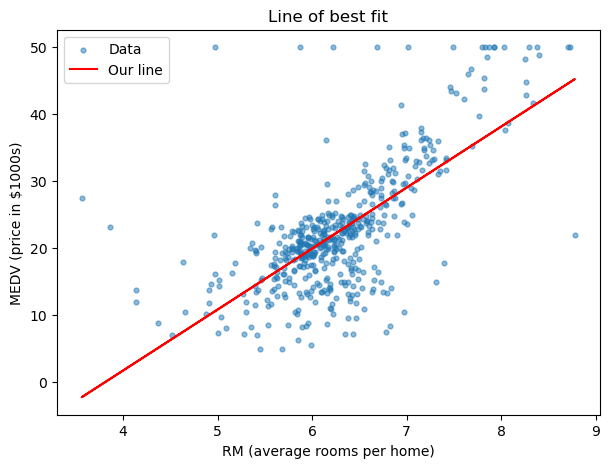

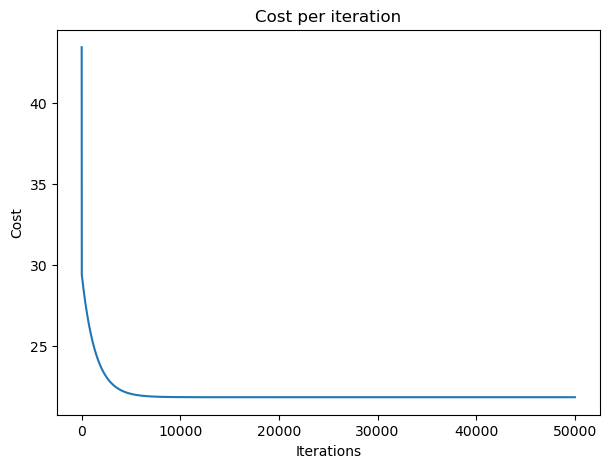

In [8]:
import matplotlib.pyplot as plt

# The data as dots and the line we found on top.
plt.figure(figsize=(7, 5))
plt.scatter(X, y, s=12, alpha=0.5, label='Data')
plt.plot(X, predict(X_b, theta), color='red', label='Our line')
plt.xlabel('RM (average rooms per home)')
plt.ylabel('MEDV (price in $1000s)')
plt.title('Line of best fit')
plt.legend()
plt.show()

# Cost per iteration. I only plot the first 1000 iterations, because
# after that the line is flat and the drop cannot be seen.
plt.figure(figsize=(7, 5))
plt.plot(cost_history)
plt.xlabel('Iterations')
plt.ylabel('Cost')
plt.title('Cost per iteration')
plt.show()

## Part 4 – Linear Regression Using scikit-learn

In [9]:
from sklearn.linear_model import LinearRegression

# scikit-learn does the same thing in two lines.
# We pass X without our column of 1s, because it adds the intercept
# by itself.
model = LinearRegression()
model.fit(X, y.ravel())

LinearRegression()

In [10]:
intercept_ = model.intercept_
coef_ = model.coef_[0]

print('scikit-learn intercept:  ', intercept_)
print('scikit-learn coefficient:', coef_)

scikit-learn intercept:   -34.67062077643851
scikit-learn coefficient: 9.1021089811803


## Part 5 – Quantitative Comparison

In [11]:
from sklearn.metrics import mean_squared_error

# Predictions from both models.
y_true = y.ravel()
y_pred_numpy = predict(X_b, theta).ravel()
y_pred_sklearn = model.predict(X)

mse_numpy = mean_squared_error(y_true, y_pred_numpy)
mse_sklearn = mean_squared_error(y_true, y_pred_sklearn)

print('Our model (NumPy):')
print('  theta0 =', theta[0, 0])
print('  theta1 =', theta[1, 0])
print('  MSE    =', mse_numpy)
print()
print('scikit-learn model:')
print('  intercept   =', intercept_)
print('  coefficient =', coef_)
print('  MSE         =', mse_sklearn)


Our model (NumPy):
  theta0 = -34.67062026022825
  theta1 = 9.10210890002943
  MSE    = 43.60055177116956

scikit-learn model:
  intercept   = -34.67062077643851
  coefficient = 9.1021089811803
  MSE         = 43.60055177116956


## Part 6 - Discussion

**1. Are the parameters from both models similar? Why?**

Yes, they came out almost the same. My model gives an intercept of -34.6706 and a slope of 9.1021,
and scikit-learn gives -34.6706 and 9.1021 as well. The MSE is 43.6005 in both cases.

I think this happens because there is only one line that fits the data best. My code walks towards
it step by step with gradient descent, and scikit-learn calculates it directly, but both end up in
the same place.

At first they did not match. With 1000 iterations my intercept was still around -10, so I kept
raising the number of iterations until the values stopped changing.

**2. What are the advantages of implementing linear regression from scratch?**

Writing it myself made me understand what each part does, I mean, the prediction, the cost that tells us how
wrong that prediction is, and the update that makes it a little better each time. When I only call
`fit()` I do not see any of that and it also made me notice that the learning rate and the number of
iterations really matter.

**3. Why is scikit-learn preferred in practice?**

Because it is much faster and much simpler to use. It gave the answer immediately, while my loop
needed 50000 iterations and about half a minute. I also do not have to pick a learning rate or worry
about whether it finished converging. And every model in the library is used the same way, with
`fit()` and `predict()`.

**4. How does the learning rate affect gradient descent?**

The learning rate is the size of the step we take on each iteration.

- If it is too small, the model learns very slowly. With `alpha = 0.001` it was still far from the
  answer after many iterations.
- If it is too big, it does not work at all. I tried `alpha = 0.05` and the cost kept growing until
  the numbers turned into `nan`.
- `alpha = 0.03` worked well.

So the learning rate has to be big enough to move forward, but small enough not to jump over the
minimum.

My struggle at this point is not knowing what learning rate to use, and just play with it until
I get a good one. My expectation also is to learn techniques that help with it.